# Figure panels — `mouse_0403L`

Panels for the fellowship figure. **Every plotting call is written out in the cell that draws it** —
no wrapper functions. To change a panel, edit its cell and re-run it.

Each panel cell has the same shape:

```
# ---- SETTINGS ----   plain variables: day, window, colours, sizes, labels
  ... data lines ...   a few lines pulling the window out
  ... plotting ...     explicit matplotlib: ax.plot, ax.axvspan, ax.set_...
  ... save ...         PDF + PNG
```

Only data loading is factored out (cell 2) — the same tools the other notebooks use.

### Three measured facts the panels depend on

* **No session has a trial in its first 60 s** — the task waits for baseline, and the earliest
  trial on any day here starts at 60–71 s. `START_MIN = None` therefore means *just before the
  first trial of the chosen phase*, not the start of the session.
* **Panel 2 is in seconds.** The reference figure is labelled "Time (min)" but its values match
  seconds: correct-trial time-to-reward gives medians 1.37 / 2.37 / 4.83 / 1.50 / 0.88 / 0.95 for
  Days 1–6, and the ~20 ceiling is the miss timeout. Set `UNIT_DIV = 60.0` for minutes.
* **The flat tops at 13.100 octaves are the reward tone**, not the cursor: during reward the task
  clamps the speaker to a constant 8777.2 Hz for ~1 s. `REWARD_TONE` draws, dims or hides them.

Smoothing is **display-only** throughout: `SMOOTH_SEC` on the cursor and `SMOOTH_SIGMA` on the
projected PC path. Set either to 0 to see the raw signal.

## 1 · Setup — imports, global style, saving

In [116]:
%matplotlib inline
import sys, warnings
from pathlib import Path
from functools import lru_cache
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
from scipy.ndimage import gaussian_filter1d

REPO = Path.cwd(); sys.path.insert(0, str(REPO / "utilities"))
import importlib
import neural_analysis_utils as na; importlib.reload(na)
import cursor_analysis_utils as ca; importlib.reload(ca)
import richfile as rfs; na.register_richfile_types(rfs)

MOUSE            = "mouse_0403L"
CURSOR_COLUMN    = "freqToOutput"         # any of ca.CURSOR_SOURCES
CURSOR_TRANSFORM = None                 # "log2" -> octaves, None -> raw Hz
DATA_ROOT        = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
FIG_DIR          = REPO / "output" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
SR, BIN          = 30, 5                  # 30 Hz raw; neural binned by 5 -> 6 Hz
SRB              = SR / BIN
MISS_SEC         = 20.0
LEAD_IN_SEC      = 5.0                    # with START_MIN=None, begin this long before the 1st trial

# ---- global style: edit and re-run this cell to restyle every panel ----
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False,
    "axes.linewidth": 0.9, "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.alpha": 0.25,
    "figure.dpi": 130, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",   # editable text in Illustrator
})

def save_fig(fig, name, formats=("pdf", "png"), dpi=400):
    for f in formats:
        fig.savefig(FIG_DIR / f"{name}.{f}", format=f, dpi=dpi, bbox_inches="tight")
    print("saved " + ", ".join(f"{name}.{f}" for f in formats))

print(f"figures -> {FIG_DIR.relative_to(REPO)}")

figures -> output\figures


In [2]:
ca.CURSOR_SOURCES

['freqToOutput',
 'cursor_output',
 'cursor_brain',
 'cursor_brain_raw',
 'voltage_cursorCurrentPos',
 'data_ws_cursor']

## 2 · Data loading

The only factored-out code. `day_of(3)` means "Day 3" counted from the animal's day-0 session;
a date string works too.

In [117]:
R = na.open_mouse(rfs, DATA_ROOT, MOUSE)
DAYS = na.get_day_list(R)
_d0 = R["date_day0"].load()
_d0 = str(np.asarray(_d0).ravel()[0]) if not isinstance(_d0, str) else _d0
DAY0_IDX = DAYS.index(_d0) if _d0 in DAYS else 0

def day_of(d):       return d if isinstance(d, str) else DAYS[DAY0_IDX + int(d)]
def day_number(day): return DAYS.index(day) - DAY0_IDX

@lru_cache(maxsize=64)
def get_cursor(day):
    return ca.load_cursor_signal(R, day, column=CURSOR_COLUMN, transform=CURSOR_TRANSFORM,
                                 max_gap_sec=0.5, sr=SR)

@lru_cache(maxsize=64)
def get_override(day):
    '''True where the speaker plays the fixed reward tone instead of the cursor.'''
    return ca.load_reward_override(R, day) > 0

@lru_cache(maxsize=64)
def get_trials(day):
    tr = na.get_true_bmi_trials(na.get_trials_df(R, day))
    rew = na.get_active_reward_frames(R, day)
    eff = na.effective_trial_end(tr, reward_frames=rew, miss_dur_sec=MISS_SEC, sr=SR)
    blocks = na.segment_factor_blocks(tr)
    return dict(tr=tr, rew=np.asarray(rew, float), eff=np.asarray(eff, float), blocks=blocks,
                phase="remap" if len(blocks) == 3 else "stable")

@lru_cache(maxsize=16)
def get_neural(day):
    return na.bin_and_zscore(na.load_neural(R, day), BIN)     # (neurons, bins) at SRB Hz

def smooth_trace(x, sigma_sec, sr=SR):
    '''DISPLAY-ONLY Gaussian smoothing of a 1-D trace, NaN-safe. sigma_sec=0 turns it off.

    The animation smoothed the cursor by binning it to 6 Hz; this is the same idea with a
    tunable width. NaN gaps are not filled in: the signal and a validity mask are smoothed
    separately and divided, so a gap stays a gap instead of smearing across it.'''
    if not sigma_sec:
        return np.asarray(x, float)
    x = np.asarray(x, float)
    ok = np.isfinite(x).astype(float)
    num = gaussian_filter1d(np.where(np.isfinite(x), x, 0.0), sigma_sec * sr, mode="nearest")
    den = gaussian_filter1d(ok, sigma_sec * sr, mode="nearest")
    return np.where(den > 1e-6, num / den, np.nan)

@lru_cache(maxsize=16)
def solution_templates(day, endpoint_sec=0.5):
    '''(T_int, T_new): the two solution states the animations mark with an X, or None.

    Each is the mean population state over the last `endpoint_sec` of a correct trial --
    T_int over the pre-rotation (intuitive) block, T_new over the LATE HALF of the new-axis
    block, so T_new reflects the solution once it has been found. Remapping days only.'''
    d = get_trials(day)
    if d["phase"] != "remap":
        return None
    X, trb = get_neural(day), na.bin_trials(d["tr"], BIN)
    w = max(int(round(endpoint_sec * SRB)), 1)
    def ends(blk, late_half=False):
        idx = [i for i in range(blk.first_trial, blk.last_trial + 1) if trb.success[i] == 1]
        if late_half:
            idx = idx[len(idx) // 2:]
        out = []
        for i in idx:
            s_, e_ = max(int(round(trb.start[i])), 0), min(int(round(trb.end[i])), X.shape[1])
            if e_ > s_:
                out.append(X[:, max(e_ - w, s_):e_].mean(1))
        return np.array(out) if out else np.empty((0, X.shape[0]))
    I, N = ends(d["blocks"][0]), ends(d["blocks"][1], late_half=True)
    return (I.mean(0), N.mean(0)) if (len(I) >= 5 and len(N) >= 5) else None

PHASE_IDX = {"intuitive_pre": 0, "new": 1, "washout": 2}

def window_frames(day, phase, start_min, dur_sec):
    '''Frame bounds of a window. start_min=None -> LEAD_IN_SEC before the phase's first trial,
    because every session opens with ~60 s of baseline in which no trial happens.'''
    d, n = get_trials(day), len(get_cursor(day))
    if phase in (None, "all") or d["phase"] != "remap":
        p0, p1 = 0.0, n / SR / 60
    else:
        i = PHASE_IDX[phase]
        p0 = d["blocks"][i].start_frame / SR / 60
        p1 = (d["blocks"][i + 1].start_frame if i < 2 else n) / SR / 60
    if start_min is None:
        st = np.asarray(d["tr"].start, float)
        st = st[np.isfinite(st) & (st >= p0 * 60 * SR) & (st < p1 * 60 * SR)]
        t0 = max(st.min() / SR / 60 - LEAD_IN_SEC / 60, p0) if len(st) else p0
    else:
        t0 = float(start_min)
    f0 = max(int(round(t0 * 60 * SR)), 0)
    return f0, min(f0 + int(round(dur_sec * SR)), n), p0

REMAP_DAYS = [d for d in DAYS if get_trials(d)["phase"] == "remap"]
CURSOR_UNIT = "octaves" if CURSOR_TRANSFORM == "log2" else "Hz"
print(f"{MOUSE}: {len(DAYS)} sessions | Day 1 = {day_of(1)} | first remapping day = {REMAP_DAYS[0]}"
      f" (Day {day_number(REMAP_DAYS[0])})")

mouse_0403L: 36 sessions | Day 1 = 20230705 | first remapping day = 20230725 (Day 21)


## 3 · Panel 1 — one cursor trace

`PHASE` is `None`, `"intuitive_pre"`, `"new"` or `"washout"`. `START_MIN = None` starts just before
the phase's first trial; give a number (minutes) to override.

saved panel1_cursor_trace.pdf, panel1_cursor_trace.png


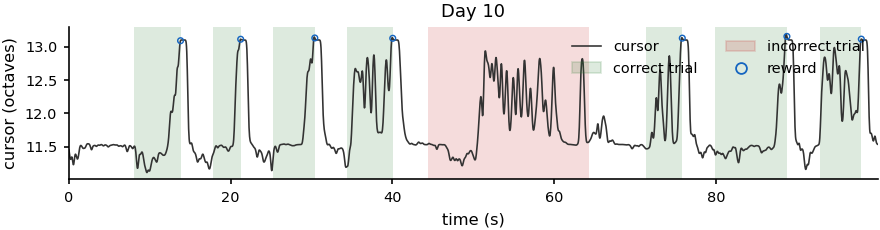

In [45]:
# ================= SETTINGS =================
DAY        = 10   #9,10,7           # int = "Day n" from day-0, or a date string like "20230725"
PHASE      = None           # None | "intuitive_pre" | "new" | "washout"
START_MIN  = 23.45  #21,23, 25         # None = just before the first trial of the phase
DUR_SEC    = 100 

FIGSIZE    = (7.0, 2.0)
CURSOR_COL = "0.20"
LW         = 0.9
SMOOTH_SEC = 0.10           # display-only Gaussian smoothing of the cursor; 0 = raw 30 Hz
REWARD_TONE = "draw"         # "draw" | "dim" | "hide"   (flat 13.1 tops = reward tone)
TONE_COL   = "0.74"

SHADE_TRIALS  = True
COL_CORRECT   = "#2E7D32"
COL_INCORRECT = "#C62828"
SHADE_ALPHA   = 0.16

MARK_REWARDS = True
REWARD_COL   = "#1565C0"
REWARD_SIZE  = 10

XLABEL  = "time (s)"
YLABEL  = f"cursor ({CURSOR_UNIT})"
TITLE   = None              # None -> "Day n"
YLIM    = None              # e.g. (10.5, 14)
LEGEND  = True                   # True -> show legend
SAVE_AS = "panel1_cursor_trace"
# ============================================

day = day_of(DAY)
f0, f1, _ = window_frames(day, PHASE, START_MIN, DUR_SEC)
cur = smooth_trace(get_cursor(day)[f0:f1], SMOOTH_SEC)
d   = get_trials(day)
t   = (np.arange(f0, f1) - f0) / SR                      # seconds from window start

fig, ax = plt.subplots(figsize=FIGSIZE)

# --- trial shading ---
if SHADE_TRIALS:
    for s, e, ok in zip(d["tr"].start, d["eff"], d["tr"].success):
        if not (np.isfinite(s) and np.isfinite(e)) or e <= f0 or s >= f1:
            continue
        ax.axvspan((max(s, f0) - f0) / SR, (min(e, f1) - f0) / SR,
                   color=COL_CORRECT if ok == 1 else COL_INCORRECT,
                   alpha=SHADE_ALPHA, lw=0, zorder=0)

# --- the cursor, with reward-tone samples split off if asked ---
cur_main = cur
if REWARD_TONE in ("dim", "hide"):
    ovr = get_override(day)[f0:f1]
    if len(ovr) < len(cur):
        ovr = np.concatenate([ovr, np.zeros(len(cur) - len(ovr), bool)])
    if REWARD_TONE == "dim":
        ax.plot(t, np.where(ovr, cur, np.nan), color=TONE_COL, lw=LW, zorder=1.5)
    cur_main = np.where(ovr, np.nan, cur)
ax.plot(t, cur_main, color=CURSOR_COL, lw=LW, zorder=2)

# --- rewards ---
if MARK_REWARDS:
    rw = d["rew"][(d["rew"] >= f0) & (d["rew"] < f1)].astype(int)
    ax.scatter((rw - f0) / SR, cur[rw - f0], s=REWARD_SIZE, facecolor="none",
               edgecolor=REWARD_COL, lw=0.8, zorder=4)

ax.set_xlim(t[0], t[-1])
if YLIM: ax.set_ylim(YLIM)
ax.set_xlabel(XLABEL); ax.set_ylabel(YLABEL)
ax.set_title(TITLE if TITLE is not None
             else f"Day {day_number(day)}" + (f" · {PHASE}" if PHASE else ""))
if LEGEND:
    h = [Line2D([], [], color=CURSOR_COL, lw=LW, label="cursor")]
    if REWARD_TONE == "dim":
        h.append(Line2D([], [], color=TONE_COL, lw=LW, label="reward tone"))
    if SHADE_TRIALS:
        h += [Patch(color=COL_CORRECT, alpha=SHADE_ALPHA, label="correct trial"),
              Patch(color=COL_INCORRECT, alpha=SHADE_ALPHA, label="incorrect trial")]
    if MARK_REWARDS:
        h.append(Line2D([], [], ls="none", marker="o", mfc="none", mec=REWARD_COL, label="reward"))
    ax.legend(handles=h, loc="upper right", ncol=2)
fig.tight_layout()
if SAVE_AS: save_fig(fig, SAVE_AS)

## 4 · Panel 2 — performance across days

Box + points, one group per day. The values are built explicitly in the loop — swap the commented
line to use all trials instead of correct ones.

saved panel2_performance.pdf, panel2_performance.png


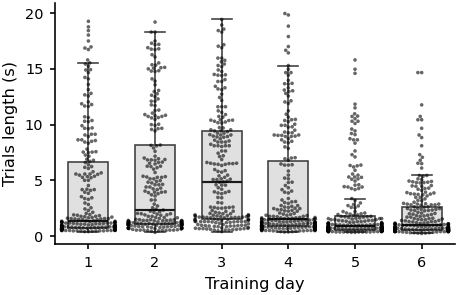

In [92]:
# ================= SETTINGS =================
DAYS_TO_PLOT = [1, 2, 3, 4, 5, 6]
UNIT_DIV     = 1.0          # 1.0 -> seconds, 60.0 -> minutes
YLABEL       = "Trials length (s)"
XLABEL       = "Training day"

FIGSIZE     = (3.75, 2.5)
DAY_COLORS  = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
DAY_COLORS  = ["#000000", "#000000", "#000000", "#000000", "#000000", "#000000"]
BOX_COLOR   = "0.88"
BOX_WIDTH   = 0.6
BOX_LW      = 0.9
WHIS        = 1.5
POINT_STYLE = "swarm"       # "swarm" | "strip"
POINT_SIZE  = 2
POINT_ALPHA = 0.6
JITTER      = 0.22

YLIM    = None
LEGEND  = False
SAVE_AS = "panel2_performance"
# ============================================

rows = []
for n in DAYS_TO_PLOT:
    day = day_of(n)
    d = get_trials(day)
    dur = (d["eff"] - d["tr"].start) / SR / UNIT_DIV
    keep = d["tr"].success == 1               # correct trials only
    # keep = np.isfinite(dur)                 # <- swap in for ALL trials
    v = dur[keep & np.isfinite(dur)]
    rows.append(pd.DataFrame(dict(day=n if isinstance(n, str) else f"{n}", value=v)))
perf = pd.concat(rows, ignore_index=True)
order = list(dict.fromkeys(perf.day))
pal = DAY_COLORS[:len(order)]

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.boxplot(data=perf, x="day", y="value", order=order, ax=ax, width=BOX_WIDTH, whis=WHIS,
            showfliers=False, color=BOX_COLOR, linewidth=BOX_LW,
            boxprops=dict(edgecolor="0.25"), medianprops=dict(color="0.1", lw=1.2),
            whiskerprops=dict(color="0.25"), capprops=dict(color="0.25"), zorder=1)
pt = dict(data=perf, x="day", y="value", order=order, hue="day", hue_order=order,
          palette=pal, ax=ax, legend=False, zorder=3, size=POINT_SIZE, alpha=POINT_ALPHA)
if POINT_STYLE == "swarm":
    sns.swarmplot(warn_thresh=1.0, **pt)
else:
    sns.stripplot(jitter=JITTER, **pt)

ax.set_xlabel(XLABEL); ax.set_ylabel(YLABEL)
if YLIM: ax.set_ylim(YLIM)
if LEGEND:
    ax.legend(handles=[Line2D([], [], ls="none", marker="o", ms=4, color=c, label=l)
                       for l, c in zip(order, pal)],
              loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
if SAVE_AS: save_fig(fig, SAVE_AS)

#display(perf.groupby("day").value.describe()[["count", "25%", "50%", "75%", "max"]].round(2))

## 5 · Panel 3 — six days stacked

One row per day. `START_MIN` / `DUR_SEC` take a single value for all rows, or a list with one entry
per day.

saved panel3_six_day_traces.pdf, panel3_six_day_traces.png


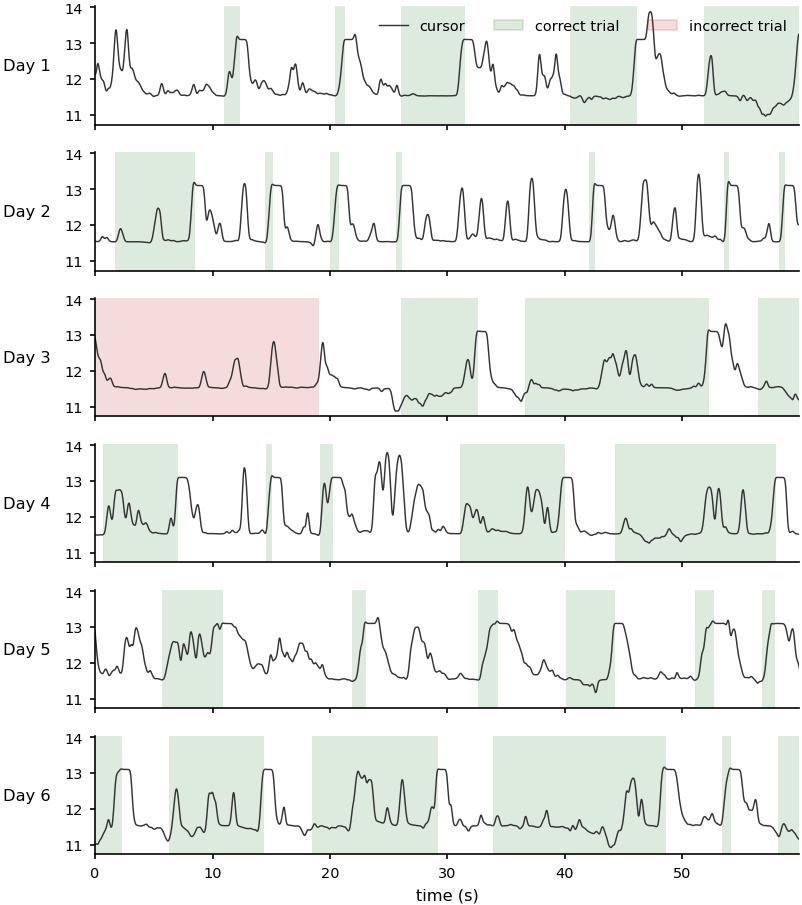

In [6]:
# ================= SETTINGS =================
DAYS_TO_PLOT = [1, 2, 3, 4, 5, 6]
PHASE        = None
START_MIN    = 5.0          # number, or a list like [5, 5, 10, 5, 5, 5]
DUR_SEC      = 60           # number, or a list

FIGSIZE     = (6.4, 7.2)
HSPACE      = 0.35
SHAREY      = True
CURSOR_COL  = "0.20"
LW          = 0.8
SMOOTH_SEC  = 0.10          # display-only Gaussian smoothing of the cursor; 0 = raw 30 Hz
REWARD_TONE = "draw"        # "draw" | "dim" | "hide"
TONE_COL    = "0.74"

SHADE_TRIALS  = True
COL_CORRECT   = "#2E7D32"
COL_INCORRECT = "#C62828"
SHADE_ALPHA   = 0.16

ROW_LABELS = True           # day name on the left of each row
XLABEL     = "time (s)"
YLIM       = None
LEGEND_ROW = 0              # which row carries the legend, or None
SAVE_AS    = "panel3_six_day_traces"
# ============================================

starts = START_MIN if isinstance(START_MIN, (list, tuple)) else [START_MIN] * len(DAYS_TO_PLOT)
durs   = DUR_SEC   if isinstance(DUR_SEC,   (list, tuple)) else [DUR_SEC]   * len(DAYS_TO_PLOT)

fig, axes = plt.subplots(len(DAYS_TO_PLOT), 1, figsize=FIGSIZE, sharey=SHAREY, sharex=True)
axes = np.atleast_1d(axes)

for i, (ax, n, s_min, du) in enumerate(zip(axes, DAYS_TO_PLOT, starts, durs)):
    day = day_of(n)
    f0, f1, _ = window_frames(day, PHASE, s_min, du)
    cur = smooth_trace(get_cursor(day)[f0:f1], SMOOTH_SEC)
    d   = get_trials(day)
    t   = (np.arange(f0, f1) - f0) / SR

    if SHADE_TRIALS:
        for s, e, ok in zip(d["tr"].start, d["eff"], d["tr"].success):
            if not (np.isfinite(s) and np.isfinite(e)) or e <= f0 or s >= f1:
                continue
            ax.axvspan((max(s, f0) - f0) / SR, (min(e, f1) - f0) / SR,
                       color=COL_CORRECT if ok == 1 else COL_INCORRECT,
                       alpha=SHADE_ALPHA, lw=0, zorder=0)

    cur_main = cur
    if REWARD_TONE in ("dim", "hide"):
        ovr = get_override(day)[f0:f1]
        if len(ovr) < len(cur):
            ovr = np.concatenate([ovr, np.zeros(len(cur) - len(ovr), bool)])
        if REWARD_TONE == "dim":
            ax.plot(t, np.where(ovr, cur, np.nan), color=TONE_COL, lw=LW, zorder=1.5)
        cur_main = np.where(ovr, np.nan, cur)
    ax.plot(t, cur_main, color=CURSOR_COL, lw=LW, zorder=2)

    ax.set_xlim(t[0], t[-1])
    if YLIM: ax.set_ylim(YLIM)
    if ROW_LABELS:
        ax.set_ylabel(n if isinstance(n, str) else f"Day {n}",
                      rotation=0, ha="right", va="center", labelpad=8)
    if LEGEND_ROW is not None and i == LEGEND_ROW and SHADE_TRIALS:
        ax.legend(handles=[Line2D([], [], color=CURSOR_COL, lw=LW, label="cursor"),
                           Patch(color=COL_CORRECT, alpha=SHADE_ALPHA, label="correct trial"),
                           Patch(color=COL_INCORRECT, alpha=SHADE_ALPHA, label="incorrect trial")],
                  loc="upper right", ncol=3)
    ax.set_xlabel(XLABEL if i == len(DAYS_TO_PLOT) - 1 else "")

fig.subplots_adjust(hspace=HSPACE); fig.tight_layout()
if SAVE_AS: save_fig(fig, SAVE_AS)

## 6 · Panel 4 — cursor + neural trajectory for one window

Two **separate** figures for the same window.

Following the trajectory animations: the PCA space is fitted on the **whole day** (`PCA_ON="day"`)
and only the selected window is drawn, the path is coloured by trial state, and the faint raw
underlay is off (`SHOW_RAW=False`) as it is in the animation.

The marked endpoints are the two **solution states**, exactly as the animation marks them:
$T_{int}$ (mean population state over the last `ENDPOINT_SEC` of pre-rotation correct trials)
and $T_{new}$ (the same over the **late half** of new-axis correct trials, so it reflects the
solution once found). They exist only on remapping days. The **mean baseline position** is also
marked (canonical baseline: ≥10 s from any trial).

Both the cursor (`SMOOTH_SEC`) and the projected path (`SMOOTH_SIGMA`) are smoothed for display
only — the smoothing never touches the neural data or any number.

In [1]:
# ================= SETTINGS =================
DAY       = REMAP_DAYS[0]   # first remapping day; any day works
PHASE     = "new"           # None | "intuitive_pre" | "new" | "washout"
START_MIN = 8.9  #int:8.9; serch: 13.9 #new 44,  54.93
DUR_SEC   = 50

# -- cursor figure --
CUR_FIGSIZE = (3.25, 1.2)
CURSOR_COL  = "0.20"
CUR_LW      = 0.9
SMOOTH_SEC  = 0.10          # display-only smoothing of the cursor; 0 = raw 30 Hz
REWARD_TONE = "draw"         # "draw" | "dim" | "hide"
TONE_COL    = "0.74"

# -- trajectory figure --
TRAJ_FIGSIZE = (3.5, 3.5)
N_PC         = 6
PCS          = (0, 1)       # which PCs on (x, y)
PCA_ON       = "day"        # "day" (whole session) | "window"
SMOOTH_SIGMA = 2.0          # display-only smoothing of the projected path, in 6 Hz bins
SHOW_RAW     = False        # faint unsmoothed path underneath; off, as in the animation
RAW_COL      = "0.86"
TRAJ_LW      = 1.8          # line width DURING TRIALS (the coloured segments)
TRAJ_LW_ITI  = 0.7          # line width during inter-trial / baseline (the grey segments)

COLOR_BY_OUTCOME = True
COL_CORRECT      = "#2E7D32"
COL_INCORRECT    = "#C62828"
COL_ITI          = "0.78"

# endpoints = the two SOLUTION states, as in the animation (not per-window circles)
MARK_TEMPLATES = True; TPL_SIZE = 170; COL_TINT = "#7f3f98"; COL_TNEW = "#f7941d"
ENDPOINT_SEC   = 0.5        # last-N-s of a correct trial that defines a solution state
MARK_BASELINE  = True; BASE_SIZE = 100; BASE_COL = "#121213"   # teal: must not clash with T_new

SHADE_TRIALS = True; SHADE_ALPHA = 0.16
EQUAL_ASPECT = False
TRAJ_XLIM = [-15, 10]; TRAJ_YLIM = [-7, 13]
LEGEND  = True
SAVE_AS = "panel4"          # -> panel4_cursor.pdf and panel4_trajectory.pdf
label_size = 13
# ============================================

day = day_of(DAY)
f0, f1, _ = window_frames(day, PHASE, START_MIN, DUR_SEC)
d   = get_trials(day)
cur = smooth_trace(get_cursor(day)[f0:f1], SMOOTH_SEC)
t   = (np.arange(f0, f1) - f0) / SR

# ---------------- figure A: cursor ----------------
figA, axA = plt.subplots(figsize=CUR_FIGSIZE)
if SHADE_TRIALS:
    for s, e, ok in zip(d["tr"].start, d["eff"], d["tr"].success):
        if not (np.isfinite(s) and np.isfinite(e)) or e <= f0 or s >= f1:
            continue
        axA.axvspan((max(s, f0) - f0) / SR, (min(e, f1) - f0) / SR,
                    color=COL_CORRECT if ok == 1 else COL_INCORRECT,
                    alpha=SHADE_ALPHA, lw=0, zorder=0)
cur_main = cur
if REWARD_TONE in ("dim", "hide"):
    ovr = get_override(day)[f0:f1]
    if len(ovr) < len(cur):
        ovr = np.concatenate([ovr, np.zeros(len(cur) - len(ovr), bool)])
    if REWARD_TONE == "dim":
        axA.plot(t, np.where(ovr, cur, np.nan), color=TONE_COL, lw=CUR_LW, zorder=1.5)
    cur_main = np.where(ovr, np.nan, cur)
axA.plot(t, cur_main, color=CURSOR_COL, lw=CUR_LW, zorder=2)
axA.set_xlim(t[0], t[-1])
axA.set_xlabel("time (s)", size=label_size); axA.set_ylabel(f"cursor", size=label_size)
axA.set_yticks([])
#axA.set_title(f"Day {day_number(day)} · {PHASE or 'session'}")
figA.tight_layout()

# ---------------- figure B: PC trajectory ----------------
X = get_neural(day)                                   # (neurons, bins)
T = X.shape[1]
b0, b1 = int(f0 // BIN), min(int(f1 // BIN), T)
sub = na.fit_subspace((X.T if PCA_ON == "day" else X[:, b0:b1].T), N_PC)   # ONE PCA space
P   = sub.project(X[:, b0:b1].T)

trb  = na.bin_trials(d["tr"], BIN)
rewb = na.bin_frames(d["rew"], BIN)
lab  = na.label_timepoints(trb, T, sr=SRB)[b0:b1]

iv   = na.baseline_intervals(trb, T, sr=SRB, reward_frames=rewb, miss_dur_sec=MISS_SEC)
idx  = np.concatenate([np.arange(a, b) for a, b in iv]) if iv else np.array([], int)
base = sub.project(X[:, idx].T).mean(0) if len(idx) else np.full(N_PC, np.nan)

a, b = PCS
raw = P[:, [a, b]]
pts = gaussian_filter1d(P, SMOOTH_SIGMA, axis=0, mode="nearest")[:, [a, b]] if SMOOTH_SIGMA else raw
if COLOR_BY_OUTCOME:
    cols = np.where(lab[:-1] == na.STATE_CORRECT, COL_CORRECT,
                    np.where(lab[:-1] == na.STATE_INCORRECT, COL_INCORRECT, COL_ITI))
else:
    cols = np.full(len(pts) - 1, CURSOR_COL)

figB, axB = plt.subplots(figsize=TRAJ_FIGSIZE)
if SHOW_RAW and SMOOTH_SIGMA:
    axB.plot(raw[:, 0], raw[:, 1], color=RAW_COL, lw=0.4, zorder=0)
# per-segment width: thin through the ITI, thick during trials
lws = (np.where(lab[:-1] == na.STATE_ITI, TRAJ_LW_ITI, TRAJ_LW)
       if COLOR_BY_OUTCOME else np.full(len(pts) - 1, TRAJ_LW))
axB.add_collection(LineCollection(np.stack([pts[:-1], pts[1:]], axis=1),
                                  colors=cols, linewidths=lws, zorder=2))
tpl = solution_templates(day, ENDPOINT_SEC)
if MARK_TEMPLATES and tpl is not None:
    p_int, p_new = sub.project(tpl[0][None, :])[0], sub.project(tpl[1][None, :])[0]
    axB.scatter(p_int[a], p_int[b], s=TPL_SIZE, marker="X", color=COL_TINT,
                edgecolor="w", lw=0.8, zorder=9, alpha=0.8)
    axB.scatter(p_new[a], p_new[b], s=TPL_SIZE, marker="X", color=COL_TNEW,
                edgecolor="w", lw=0.8, zorder=9, alpha=0.8)
if MARK_BASELINE and np.isfinite(base).all():
    axB.scatter(base[a], base[b], s=BASE_SIZE, marker="s", color=BASE_COL,
                edgecolor="w", lw=0.4, zorder=8, alpha=0.8)
axB.autoscale()
if TRAJ_XLIM: axB.set_xlim(TRAJ_XLIM)
if TRAJ_YLIM: axB.set_ylim(TRAJ_YLIM)
if EQUAL_ASPECT: axB.set_aspect("equal", adjustable="datalim")
axB.set_xlabel(f"PC{a+1}  ({100*sub.explained_ratio[a]:.1f}%)", size=label_size)
axB.set_yticks([-5, 0, 5, 10])
axB.set_ylabel(f"PC{b+1}  ({100*sub.explained_ratio[b]:.1f}%)", size=label_size)
#axB.set_title(f"Day {day_number(day)} · {DUR_SEC:g} s window")
if LEGEND:
    h = []
    if COLOR_BY_OUTCOME:
        h = [Line2D([], [], color=COL_CORRECT, lw=TRAJ_LW, label="correct trial (CT)"),
            Line2D([], [], color=COL_INCORRECT, lw=TRAJ_LW, label="incorrect trial (ICT)"),
             Line2D([], [], color=COL_ITI, lw=TRAJ_LW_ITI, label="inter-trial interval (ITI)")]
    if MARK_TEMPLATES and tpl is not None:
        h += [Line2D([], [], ls="none", marker="X", color=COL_TINT, label="CT mean endpoint"),
              Line2D([], [], ls="none", marker="X", color=COL_TNEW, label="ICT mean endpoint")]
    if MARK_BASELINE:
        h.append(Line2D([], [], ls="none", marker="s", color=BASE_COL, label="ITI  mean"))
    axB.legend(handles=h, loc="upper left")
figB.tight_layout()

if (lab != na.STATE_ITI).sum() == 0:
    print("  note: no trials in this window - the path is all grey. Try START_MIN=None or PHASE='new'.")
if SAVE_AS:
    save_fig(figA, f"{SAVE_AS}_cursor"); save_fig(figB, f"{SAVE_AS}_trajectory")

NameError: name 'REMAP_DAYS' is not defined

saved panel4_cursor.pdf, panel4_cursor.png
saved panel4_trajectory.pdf, panel4_trajectory.png


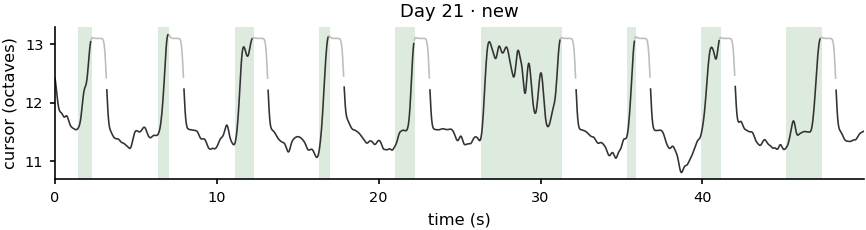

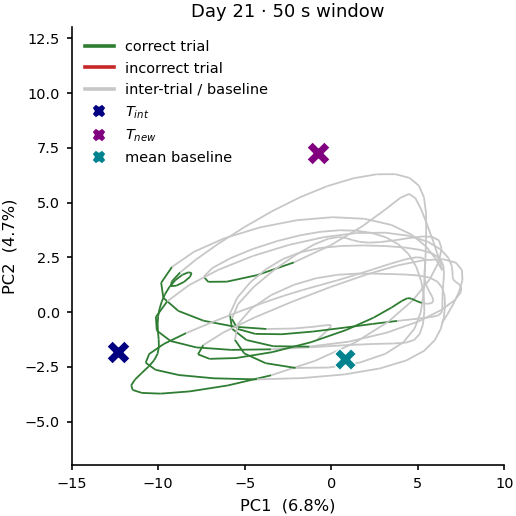

## 7 · Checks

In [8]:
checks = []
def chk(name, ok, detail=""):
    checks.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))

chk("Day 1 resolves from day-0", day_of(1) == DAYS[DAY0_IDX + 1], day_of(1))
chk("panel 2 within the 20 s timeout", perf.value.max() <= MISS_SEC / UNIT_DIV + 0.5,
    f"max = {perf.value.max():.2f}")
chk("PCA fitted on the whole day, not the window", P.shape[0] < T, f"{P.shape[0]} of {T} bins drawn")
chk("trajectory finite", bool(np.isfinite(P).all()))
chk("mean baseline defined", bool(np.isfinite(base).all()))
chk("solution templates T_int / T_new found", tpl is not None,
    "remapping day" if tpl is not None else "stable day -> no T_new")
chk("smoothing keeps the trace length", 
    len(smooth_trace(get_cursor(day_of(1)), 0.1)) == len(get_cursor(day_of(1))))
chk("window lands on trials", bool((lab != na.STATE_ITI).any()),
    f"{int((lab != na.STATE_ITI).sum())} of {len(lab)} bins in a trial")
chk("PDF text stays editable", mpl.rcParams["pdf.fonttype"] == 42)
chk("all panels saved a PDF", all((FIG_DIR / f"{n}.pdf").exists() for n in
    ["panel1_cursor_trace", "panel2_performance", "panel3_six_day_traces",
     "panel4_cursor", "panel4_trajectory"]))
display(pd.DataFrame(checks))
print("output/figures:  " + ", ".join(sorted(p.name for p in FIG_DIR.glob("*.pdf"))))

,check,result,detail
0,Day 1 resolves from day-0,PASS,20230705
1,panel 2 within the 20 s timeout,PASS,max = 19.97
2,"PCA fitted on the whole day, not the window",PASS,360 of 28800 bins drawn
3,trajectory finite,PASS,
4,mean baseline defined,PASS,
5,solution templates T_int / T_new found,PASS,remapping day
6,smoothing keeps the trace length,PASS,
7,window lands on trials,PASS,268 of 360 bins in a trial
8,PDF text stays editable,PASS,
9,all panels saved a PDF,PASS,


output/figures:  panel1_cursor_trace.pdf, panel2_performance.pdf, panel3_six_day_traces.pdf, panel4_cursor.pdf, panel4_trajectory.pdf
